In [1]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv("Obfuscated-MalMem2022.csv")

# 2. Check total rows and columns
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

# 3. View the first 5 rows
print("Preview:")
display(df.head())

# 4. Check for missing/null values
print(f"Total Missing Values: {df.isnull().sum().sum()}")

# 5. Check the target column balance
# In this dataset, 'Class' represents Benign vs Malware
if 'Class' in df.columns:
    print("\nClass Distribution:")
    print(df['Class'].value_counts())

Dataset Shape: 58596 rows, 57 columns

Preview:


,Category,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,...,svcscan.kernel_drivers,svcscan.fs_drivers,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric,Class
0,Benign,45,17,10.555556,0,202.844444,1694,38.500000,9129,212.302326,...,221,26,24,116,0,121,87,0,8,Benign
1,Benign,47,19,11.531915,0,242.234043,2074,44.127660,11385,242.234043,...,222,26,24,118,0,122,87,0,8,Benign
2,Benign,40,14,14.725000,0,288.225000,1932,48.300000,11529,288.225000,...,222,26,27,118,0,120,88,0,8,Benign
3,Benign,32,13,13.500000,0,264.281250,1445,45.156250,8457,264.281250,...,222,26,27,118,0,120,88,0,8,Benign
4,Benign,42,16,11.452381,0,281.333333,2067,49.214286,11816,281.333333,...,222,26,24,118,0,124,87,0,8,Benign


Total Missing Values: 0

Class Distribution:
Class
Benign     29298
Malware    29298
Name: count, dtype: int64


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load data
df = pd.read_csv("Obfuscated-MalMem2022.csv")

# 2. Encode target: Benign -> 0, Malware -> 1
y = df['Class'].map({'Benign': 0, 'Malware': 1})

# 3. Drop label columns and non-feature identifiers to prevent 100% leakage
columns_to_drop = ['Class']
if 'Category' in df.columns:
    columns_to_drop.append('Category')

X = df.drop(columns=columns_to_drop)

# Keep only numerical process metrics
X = X.select_dtypes(include=[np.number])

# 4. Train-Test Split (80% train, 20% test with stratified labels)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Features count: {X.shape[1]}")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Features count: 55
Training samples: 46876
Testing samples: 11720


In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load data
df = pd.read_csv("Obfuscated-MalMem2022.csv")

# 2. Extract Malware Families from the 'Category' column
# e.g., 'Ransomware-WannaCry' becomes 'Ransomware'
def extract_family(cat):
    if pd.isna(cat) or 'Benign' in str(cat):
        return 'Benign'
    return str(cat).split('-')[0].strip()

df['Family'] = df['Category'].apply(extract_family)
print("Target Family Distribution:")
print(df['Family'].value_counts())

# 3. Encode multi-class labels into integers (0, 1, 2, 3)
family_mapping = {'Benign': 0, 'Ransomware': 1, 'Spyware': 2, 'Trojan': 3}
y = df['Family'].map(family_mapping)

# 4. Drop non-feature labels to prevent leakage
columns_to_drop = ['Class', 'Category', 'Family']
X = df.drop(columns=[col for col in columns_to_drop if col in df.columns])
X = X.select_dtypes(include=[np.number])

# 5. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 6. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 7. Benchmarking Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(max_iter=2000, random_state=42, dual=False),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42, eval_metric='mlogloss')
}

results = []

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    # Using 'macro' averaging for balanced multi-class evaluation
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2)
    })

comparison_df = pd.DataFrame(results).sort_values(by="F1-Score (%)", ascending=False)
print("\n--- MULTI-CLASS MALWARE CLASSIFICATION RESULTS ---")
display(comparison_df)

Target Family Distribution:
Family
Benign        29298
Spyware       10020
Ransomware     9791
Trojan         9487
Name: count, dtype: int64
Training Logistic Regression...
Training Linear SVM...
Training Random Forest...
Training XGBoost...

--- MULTI-CLASS MALWARE CLASSIFICATION RESULTS ---


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
3,XGBoost,84.31,76.48,76.45,76.44
2,Random Forest,81.87,73.45,72.86,72.86
0,Logistic Regression,74.02,61.92,61.19,61.04
1,Linear SVM,73.00,60.62,59.65,59.43


Training Primary Detection Model (XGBoost)...

================ MODEL EVALUATION ================
Overall Accuracy: 84.31%

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
  Ransomware       0.67      0.65      0.66      1958
     Spyware       0.74      0.72      0.73      2004
      Trojan       0.65      0.69      0.67      1898

    accuracy                           0.84     11720
   macro avg       0.76      0.76      0.76     11720
weighted avg       0.84      0.84      0.84     11720



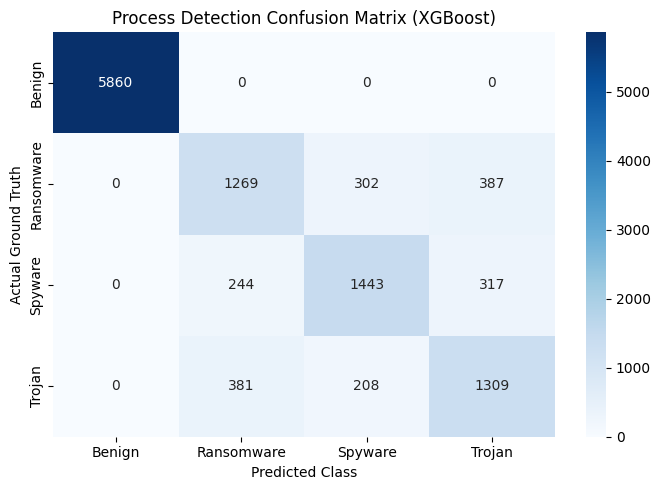

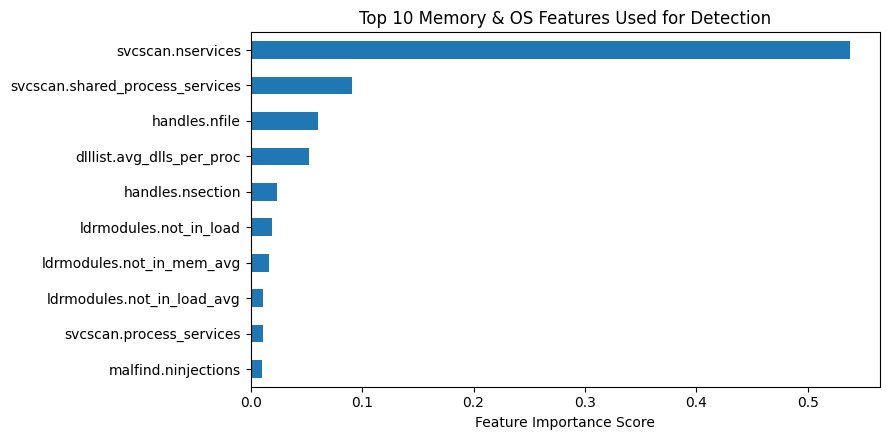

================ LIVE INFERENCE TEST ================
--- Process Inspection (Sample #12) ---
Actual Type   : Ransomware
Verdict       : SUSPICIOUS (RANSOMWARE)
Confidence    : 54.41999816894531%

--- Process Inspection (Sample #55) ---
Actual Type   : Ransomware
Verdict       : SUSPICIOUS (TROJAN)
Confidence    : 45.7599983215332%



In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Load Data & Create Multi-Class Labels
df = pd.read_csv("Obfuscated-MalMem2022.csv")

def extract_family(cat):
    if pd.isna(cat) or 'Benign' in str(cat):
        return 'Benign'
    return str(cat).split('-')[0].strip()

df['Family'] = df['Category'].apply(extract_family)
family_mapping = {'Benign': 0, 'Ransomware': 1, 'Spyware': 2, 'Trojan': 3}
class_names = ['Benign', 'Ransomware', 'Spyware', 'Trojan']
y = df['Family'].map(family_mapping)

# 2. Extract Features & Train-Test Split (80/20)
columns_to_drop = ['Class', 'Category', 'Family']
X = df.drop(columns=[col for col in columns_to_drop if col in df.columns]).select_dtypes(include=[np.number])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train the Primary Model (XGBoost)
print("Training Primary Detection Model (XGBoost)...")
model = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42, eval_metric='mlogloss')
model.fit(X_train_scaled, y_train)

# 4. Evaluation & Detailed Report
y_pred = model.predict(X_test_scaled)
print(f"\n================ MODEL EVALUATION ================")
print(f"Overall Accuracy: {round(accuracy_score(y_test, y_pred) * 100, 2)}%\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# 5. Visualization 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Process Detection Confusion Matrix (XGBoost)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Ground Truth")
plt.tight_layout()
plt.show()

# 6. Visualization 2: Top 10 Indicative Process Behaviors
feat_imp = pd.Series(model.feature_importances_, index=X.columns).nlargest(10)
plt.figure(figsize=(9, 4.5))
feat_imp.sort_values().plot(kind='barh', color='#1f77b4')
plt.title("Top 10 Memory & OS Features Used for Detection")
plt.xlabel("Feature Importance Score")
plt.tight_layout()
plt.show()

# 7. Live Demonstration Function (Shows Real-Time Detection on New Processes)
def inspect_process(sample_index):
    sample = X_test_scaled[sample_index].reshape(1, -1)
    actual_label = class_names[y_test.iloc[sample_index]]
    predicted_label = class_names[model.predict(sample)[0]]
    probabilities = model.predict_proba(sample)[0]
    
    status = "SAFE (BENIGN)" if predicted_label == "Benign" else f"SUSPICIOUS ({predicted_label.upper()})"
    print(f"--- Process Inspection (Sample #{sample_index}) ---")
    print(f"Actual Type   : {actual_label}")
    print(f"Verdict       : {status}")
    print(f"Confidence    : {round(np.max(probabilities) * 100, 2)}%\n")

print("================ LIVE INFERENCE TEST ================")
inspect_process(12)
inspect_process(55)

In [5]:
import joblib

# 1. Save the trained XGBoost model and the scaler
joblib.dump(model, 'xgboost_process_detector.pkl')
joblib.dump(scaler, 'process_scaler.pkl')

print("Model and Scaler successfully saved!")

Model and Scaler successfully saved!


In [6]:
import joblib
import numpy as np
import pandas as pd

# 1. Load the trained model and scaler
model = joblib.load('xgboost_process_detector.pkl')
scaler = joblib.load('process_scaler.pkl')

class_names = ['Benign (Safe)', 'Ransomware', 'Spyware', 'Trojan']

print("=" * 60)
print("   ML-BASED SUSPICIOUS PROCESS MONITOR: READY")
print("=" * 60)

# 2. Read dataset process features
df = pd.read_csv("Obfuscated-MalMem2022.csv")
features = df.drop(columns=[col for col in ['Class', 'Category', 'Family'] if col in df.columns]).select_dtypes(include=[np.number])

# 3. Detection function
def scan_process(sample_row_idx):
    raw_sample = features.iloc[[sample_row_idx]]
    scaled_sample = scaler.transform(raw_sample)
    
    pred_idx = model.predict(scaled_sample)[0]
    probabilities = model.predict_proba(scaled_sample)[0]
    confidence = np.max(probabilities) * 100
    verdict = class_names[pred_idx]
    
    print(f"\n[SCANNING PID / SNAPSHOT #{sample_row_idx}]")
    print(f" > Memory Services Count : {raw_sample['svcscan.nservices'].values[0]}")
    print(f" > Active File Handles   : {raw_sample['handles.nfile'].values[0]}")
    print(f" > Injected DLLs/Code    : {raw_sample['malfind.ninjections'].values[0]}")
    print(f" > Verdict               : {'[+] ' + verdict if pred_idx == 0 else '[!] ' + verdict}")
    print(f" > Confidence Level      : {confidence:.2f}%")
    if pred_idx != 0:
        print(" > ACTION TAKEN          : TERMINATE_PROCESS / ALERT_SOC")

# 4. Test diverse processes across Benign, Spyware, Ransomware, and Trojan
test_sample_ids = [10, 30000, 42000, 52000]

for sample_id in test_sample_ids:
    scan_process(sample_id)

   ML-BASED SUSPICIOUS PROCESS MONITOR: READY

[SCANNING PID / SNAPSHOT #10]
 > Memory Services Count : 395
 > Active File Handles   : 1145
 > Injected DLLs/Code    : 5
 > Verdict               : [+] Benign (Safe)
 > Confidence Level      : 99.99%

[SCANNING PID / SNAPSHOT #30000]
 > Memory Services Count : 389
 > Active File Handles   : 638
 > Injected DLLs/Code    : 3
 > Verdict               : [!] Spyware
 > Confidence Level      : 59.22%
 > ACTION TAKEN          : TERMINATE_PROCESS / ALERT_SOC

[SCANNING PID / SNAPSHOT #42000]
 > Memory Services Count : 389
 > Active File Handles   : 864
 > Injected DLLs/Code    : 63
 > Verdict               : [!] Spyware
 > Confidence Level      : 61.27%
 > ACTION TAKEN          : TERMINATE_PROCESS / ALERT_SOC

[SCANNING PID / SNAPSHOT #52000]
 > Memory Services Count : 389
 > Active File Handles   : 645
 > Injected DLLs/Code    : 3
 > Verdict               : [!] Spyware
 > Confidence Level      : 65.21%
 > ACTION TAKEN          : TERMINATE_PROCES

In [7]:
import joblib
import numpy as np
import pandas as pd

# Load saved pipeline artifacts
model = joblib.load('xgboost_process_detector.pkl')
scaler = joblib.load('process_scaler.pkl')
class_names = ['Benign (Safe)', 'Ransomware', 'Spyware', 'Trojan']

# Load column headers from the dataset to construct feature rows
df = pd.read_csv("Obfuscated-MalMem2022.csv")
feature_columns = df.drop(columns=[col for col in ['Class', 'Category', 'Family'] if col in df.columns]).select_dtypes(include=[np.number]).columns

def test_custom_process(services=395, handles=1100, injected_code=0):
    """
    Simulates testing a process by modifying key OS metrics.
    Normal system processes have high service counts and ~0 code injections.
    Malicious processes tamper with services and frequently inject shellcode.
    """
    # Start with a typical baseline feature vector (median values)
    sample_df = pd.DataFrame([df[feature_columns].median()], columns=feature_columns)
    
    # Overwrite with the metrics you want to test
    sample_df['svcscan.nservices'] = services
    sample_df['handles.nfile'] = handles
    sample_df['malfind.ninjections'] = injected_code
    
    # Scale and predict
    scaled = scaler.transform(sample_df)
    pred_idx = model.predict(scaled)[0]
    probs = model.predict_proba(scaled)[0]
    
    verdict = class_names[pred_idx]
    confidence = np.max(probs) * 100
    
    print("=" * 50)
    print(f"INPUT METRICS -> Services: {services} | Handles: {handles} | Injections: {injected_code}")
    print(f"VERDICT       : {verdict}")
    print(f"CONFIDENCE    : {confidence:.2f}%")
    if pred_idx != 0:
        print("ALERT         : [!] High risk detected - Process flagged for quarantine/termination.")
    else:
        print("STATUS        : [+] Process verified as standard system behavior.")
    print("=" * 50 + "\n")

# Scenario A: Normal Background Process (e.g., standard Windows service)
test_custom_process(services=395, handles=1140, injected_code=0)

# Scenario B: Suspicious Process (abnormal service counts + 45 unmapped memory injections)
test_custom_process(services=385, handles=650, injected_code=45)

INPUT METRICS -> Services: 395 | Handles: 1140 | Injections: 0
VERDICT       : Benign (Safe)
CONFIDENCE    : 98.45%
STATUS        : [+] Process verified as standard system behavior.

INPUT METRICS -> Services: 385 | Handles: 650 | Injections: 45
VERDICT       : Spyware
CONFIDENCE    : 36.94%
ALERT         : [!] High risk detected - Process flagged for quarantine/termination.



In [8]:
# Pass any row number between 0 and 58,595
scan_process(450)    # Tests row 450 (Benign)
scan_process(35000)  # Tests row 35,000 (Malware)


[SCANNING PID / SNAPSHOT #450]
 > Memory Services Count : 392
 > Active File Handles   : 854
 > Injected DLLs/Code    : 5
 > Verdict               : [+] Benign (Safe)
 > Confidence Level      : 99.99%

[SCANNING PID / SNAPSHOT #35000]
 > Memory Services Count : 389
 > Active File Handles   : 648
 > Injected DLLs/Code    : 3
 > Verdict               : [!] Spyware
 > Confidence Level      : 44.45%
 > ACTION TAKEN          : TERMINATE_PROCESS / ALERT_SOC


In [9]:
import sys
print(sys.executable)

C:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\python.exe
